In [63]:
import pandas as pd
import numpy as np
from sklearn.ensemble import IsolationForest
from sklearn.metrics import classification_report, roc_auc_score, f1_score, confusion_matrix, ConfusionMatrixDisplay, roc_curve
import matplotlib.pyplot as plt


In [ ]:
data = pd.read_csv("data/data_preprocessed.csv")
print("Shape du dataset :", data.shape)

Shape du dataset : (357952, 92)


Tri temporel et découpage train/val/test

In [65]:
data_processed = data.sort_values(by='time_of_day')

train_size = int(len(data_processed) * 0.7)
val_size   = int(len(data_processed) * 0.15)

train_data = data_processed.iloc[:train_size]
val_data   = data_processed.iloc[train_size:train_size + val_size]
test_data  = data_processed.iloc[train_size + val_size:]

X_train = train_data.drop(columns=['normality'])
y_train = train_data['normality']

X_val = val_data.drop(columns=['normality'])
y_val = val_data['normality']

X_test = test_data.drop(columns=['normality'])
y_test = test_data['normality']

Isolation Forest sur données normales

In [66]:
X_train_normal = X_train[y_train == 0]

iso = IsolationForest(
    n_estimators=300,
    contamination=0.1,
    random_state=42
)

iso.fit(X_train_normal)

IsolationForest(contamination=0.1, n_estimators=300, random_state=42)

Prédictions initiales et métriques

In [71]:
y_val_pred = iso.predict(X_val)
y_val_pred = (y_val_pred == -1).astype(int)  # -1 = anomalie

print("Classification report (seuil par défaut) :")
print(classification_report(y_val, y_val_pred))

# ROC-AUC sur score continu
y_scores = iso.decision_function(X_val)
roc_auc = roc_auc_score(y_val, -y_scores)  # inverser pour anomalies
print(f"ROC-AUC : {roc_auc:.4f}")


Classification report (seuil par défaut) :
              precision    recall  f1-score   support

           0       0.95      0.86      0.90     51124
           1       0.05      0.16      0.08      2568

    accuracy                           0.82     53692
   macro avg       0.50      0.51      0.49     53692
weighted avg       0.91      0.82      0.86     53692

ROC-AUC : 0.8218


Ajustement du seuil basé sur la proportion d’anomalies

In [72]:
threshold = np.percentile(y_scores, 5)  # correspond à ~5% anomalies
y_val_pred_thresh = (y_scores <= threshold).astype(int)

print("Classification report avec seuil ajusté :")
print(classification_report(y_val, y_val_pred_thresh))


Classification report avec seuil ajusté :
              precision    recall  f1-score   support

           0       0.96      0.95      0.96     51124
           1       0.14      0.15      0.15      2568

    accuracy                           0.92     53692
   macro avg       0.55      0.55      0.55     53692
weighted avg       0.92      0.92      0.92     53692



Optimisation du seuil pour F1-score

In [73]:
percentiles = np.arange(1, 20, 0.5)
best_f1 = 0
best_thresh = None

for p in percentiles:
    thresh = np.percentile(y_scores, p)
    y_pred = (y_scores <= thresh).astype(int)
    f1 = f1_score(y_val, y_pred)
    if f1 > best_f1:
        best_f1 = f1
        best_thresh = thresh

print(f"Meilleur seuil : {best_thresh:.6f} | F1 = {best_f1:.4f}")

# Appliquer le meilleur seuil
y_val_pred_best = (y_scores <= best_thresh).astype(int)

Meilleur seuil : -0.019982 | F1 = 0.1902


Matrice de confusion

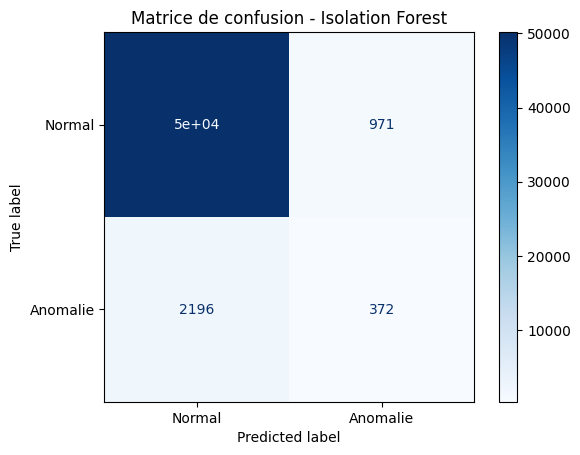

In [74]:
cm = confusion_matrix(y_val, y_val_pred_best)
disp = ConfusionMatrixDisplay(cm, display_labels=["Normal", "Anomalie"])
disp.plot(cmap="Blues")
plt.title("Matrice de confusion - Isolation Forest")
plt.show()


Courbe ROC

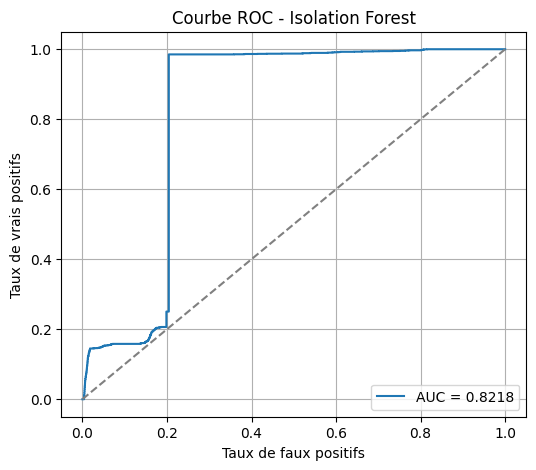

In [75]:
fpr, tpr, _ = roc_curve(y_val, -y_scores)  # inverser score
roc_auc = roc_auc_score(y_val, -y_scores)

plt.figure(figsize=(6,5))
plt.plot(fpr, tpr, label=f"AUC = {roc_auc:.4f}")
plt.plot([0,1],[0,1],"--", color="gray")
plt.xlabel("Taux de faux positifs")
plt.ylabel("Taux de vrais positifs")
plt.title("Courbe ROC - Isolation Forest")
plt.legend()
plt.grid(True)
plt.show()


Courbe PR (Precision-Recall)

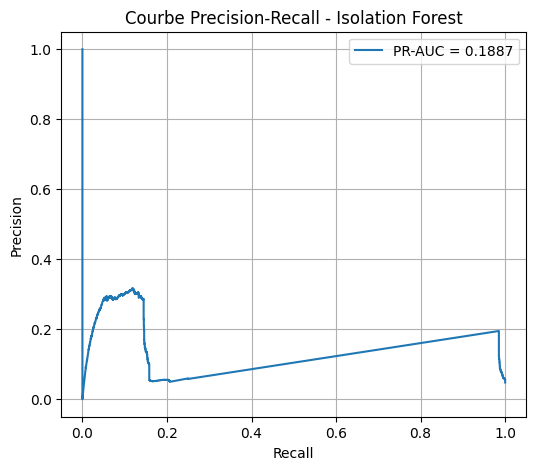

In [76]:
from sklearn.metrics import precision_recall_curve, average_precision_score

precision, recall, _ = precision_recall_curve(y_val, -y_scores)
pr_auc = average_precision_score(y_val, -y_scores)

plt.figure(figsize=(6,5))
plt.plot(recall, precision, label=f"PR-AUC = {pr_auc:.4f}")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Courbe Precision-Recall - Isolation Forest")
plt.legend()
plt.grid(True)
plt.show()


Conclusion


- Isolation Forest détecte les anomalies en utilisant uniquement les données normales.
- ROC-AUC et PR-AUC élevés indiquent une bonne capacité à identifier les anomalies.
- L’optimisation du seuil sur F1-score permet d’équilibrer précision et rappel.